# 05 · GWAS loci: the silver standard of 568 credible sets (Fig. 3)

Noncoding UK Biobank credible sets for 31 traits whose one gene within 2 Mb carries an independent coding variant for the same trait (the silver gene; Weeks et al. 2023, Gschwind et al.). Every credible-set variant with posterior inclusion probability > 0.1 was scored and genes within 1 Mb ranked; a gene's score at a credible set is its maximum over the set's variants. 14 traits were scored in a matched cell type (osteoblast, K562 or GM12878) and 17 in K562.

The table `data/gwas/silver_standard.tsv.gz` has every candidate gene with CisLink scores, the nearest-gene baseline (negative TSS distance to the highest-probability variant), the published methods' scores, and the leave-out flags used for the fair comparisons (Supplementary Table 6).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from cislink import gwas

t = pd.read_csv("../data/gwas/silver_standard.tsv.gz", sep="\t").rename(
    columns={"Credible set": "locus", "Fine-mapping region": "region", "Silver gene": "target"})
print(t.locus.nunique(), "credible sets,", t.Trait.nunique(), "traits,", t.region.nunique(), "fine-mapping regions,", len(t), "candidate genes")
METHODS = {"CisLink-V2G": False, "CisLink-E2G": False, "Nearest gene": True, "L2G": False, "PoPS": False, "cS2G": False, "ENCODE-rE2G": False, "ABC": False}

568 credible sets, 31 traits, 265 fine-mapping regions, 14549 candidate genes


## Top-1 accuracy and chance-corrected MRR (Fig. 3a)

Ties are split at random; a method whose highest score at a credible set is 0 makes no call there (`called` = share of sets with a call). Chance-corrected MRR is 0 for a random ordering.

In [2]:
s = gwas.summarize(t, METHODS)
s.round(3)

,method,loci,top1,MRR,MRR_cc,called
0,CisLink-V2G,568,0.526,0.676,0.587,1.000
1,CisLink-E2G,568,0.502,0.659,0.566,1.000
2,Nearest gene,568,0.518,0.666,0.573,1.000
3,L2G,568,0.451,0.544,0.421,0.771
4,PoPS,568,0.371,0.505,0.393,0.998
5,cS2G,568,0.311,0.414,0.251,0.600
6,ENCODE-rE2G,568,0.165,0.289,0.090,0.287
7,ABC,568,0.156,0.281,0.079,0.287


In [3]:
per = {m: gwas.per_locus(t, m, always=a) for m, a in METHODS.items()}
for b in ("Nearest gene", "PoPS", "cS2G", "ENCODE-rE2G"):
    d = gwas.region_bootstrap_difference(per["CisLink-V2G"], per[b])
    print(f"V2G - {b:12s} top-1 {d[0]:+.3f} [{d[1]:+.3f}, {d[2]:+.3f}]")

V2G - Nearest gene top-1 +0.009 [-0.007, +0.027]


V2G - PoPS         top-1 +0.155 [+0.076, +0.233]


V2G - cS2G         top-1 +0.216 [+0.168, +0.266]


V2G - ENCODE-rE2G  top-1 +0.361 [+0.304, +0.421]


## By trait (Fig. 3b)

In [4]:
bt = (pd.concat({tr: gwas.summarize(g, {"CisLink-V2G": False, "Nearest gene": True, "PoPS": False}).set_index("method").MRR_cc
                 for tr, g in t.groupby("Trait")}, axis=1).T)
bt["sets"] = t.groupby("Trait").locus.nunique()
bt.sort_values("CisLink-V2G", ascending=False).round(2)

method,CisLink-V2G,Nearest gene,PoPS,sets
CRP,0.97,0.89,-0.02,17
UA,0.89,0.90,0.83,13
ApoA,0.86,0.83,0.83,18
ApoB,0.84,0.84,0.88,9
HDLC,0.77,0.70,0.73,20
MCV,0.71,0.71,0.38,13
Ca,0.71,0.74,0.30,16
Lym,0.68,0.67,0.63,11
eBMD,0.67,0.67,0.19,20
Alb,0.65,0.56,0.25,6


## Credible sets whose silver gene is or is not the nearest gene (Fig. 3d)

The nearest gene is right at about half of the loci. Where it is not, gene-level evidence (PoPS) adds most.

In [5]:
nearest_target = t.target & (t["Nearest gene"] == t.groupby("locus")["Nearest gene"].transform("max"))
near = set(t[nearest_target].locus)
rows = []
for name, sub in (("silver gene is nearest", t[t.locus.isin(near)]), ("not the nearest", t[~t.locus.isin(near)])):
    r = gwas.summarize(sub, {m: METHODS[m] for m in ("CisLink-V2G", "CisLink-E2G", "L2G", "PoPS", "cS2G", "ENCODE-rE2G")}).set_index("method").top1
    rows.append(r.rename(f"{name} ({sub.locus.nunique()})"))
pd.concat(rows, axis=1).round(3)

,silver gene is nearest (294),not the nearest (274)
method,,
CisLink-V2G,0.959,0.062
CisLink-E2G,0.901,0.073
L2G,0.738,0.142
PoPS,0.452,0.285
cS2G,0.488,0.120
ENCODE-rE2G,0.233,0.093


## Locus-level precision-recall without L2G's training genes (Fig. 3c)

L2G's public training genes include the silver genes of 136 credible sets, so these are removed (432 sets remain). Each method calls its top gene, ordered by its top score.

432 credible sets


CisLink-V2G    0.287
L2G            0.270
CisLink-E2G    0.257
cS2G           0.139
ENCODE-rE2G    0.109
PoPS           0.097
ABC            0.093
dtype: float64

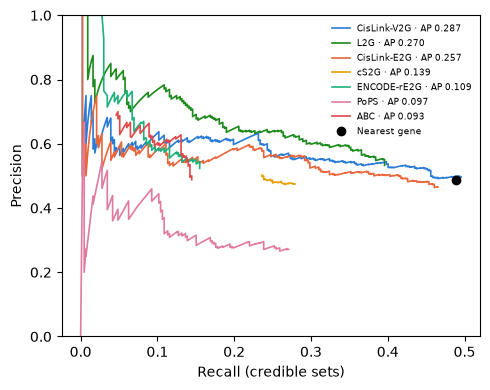

In [6]:
lo = t[~t.locus.isin(set(t[t.target & t["L2G training gene"]].locus))]
print(lo.locus.nunique(), "credible sets")
fig, ax = plt.subplots(figsize=(5, 4)); ap = {}
COLORS = {"CisLink-V2G": "#2a7bd6", "L2G": "#1a8a1a", "CisLink-E2G": "#e8663a", "cS2G": "#e8a000",
          "ENCODE-rE2G": "#1db07a", "PoPS": "#e07aa0", "ABC": "#e0484a"}
for m, c in COLORS.items():
    r = gwas.locus_pr(gwas.locus_calls(lo, m)); ap[m] = r["AP"]
    ax.plot(r["recall"], r["precision"], color=c, lw=1.2, label=f"{m} · AP {r['AP']:.3f}")
nr = gwas.per_locus(lo, "Nearest gene", always=True).top1.mean()
ax.plot([nr], [nr], "ko", label="Nearest gene"); ax.set_xlabel("Recall (credible sets)"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1)
ax.legend(fontsize=6.5, frameon=False); plt.tight_layout()
pd.Series(ap).round(3)

## Gene–locus pairs (L2G format), against the naive nearest-gene classifier

In [7]:
pd.DataFrame({m: gwas.pair_level(t, m, nearest="Nearest gene") for m in ("CisLink-V2G", "PoPS", "cS2G", "ENCODE-rE2G", "ABC")}).T.round(3)

,AP,AUROC,AP nearest,AUROC nearest
CisLink-V2G,0.354,0.907,0.287,0.749
PoPS,0.261,0.808,0.287,0.749
cS2G,0.221,0.675,0.287,0.749
ENCODE-rE2G,0.117,0.529,0.287,0.749
ABC,0.105,0.528,0.287,0.749
